<a href="https://colab.research.google.com/github/arshdeepbangar/AAI2025/blob/main/Group_6_Agentic_AI_in_Supply_Chain_CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA
Synthetic sample data: 120 days and 3 SKUs.
First 30 days: forecast initialization.
Remaining 90 days: evaluation.


sku,A,B,C
date,,,
2026-01-01,15,9,22
2026-01-02,18,10,27
2026-01-03,18,12,26
2026-01-04,15,7,25
2026-01-05,13,6,21


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level,review_period_days,max_inventory,fixed_order_cost
0,A,5,0.12,8,5,10,0.95,1,400,0
1,B,4,0.12,8,4,10,0.95,1,400,0
2,C,7,0.12,8,7,10,0.95,1,400,0



RESULTS


,policy,demand,served,lost_units,stockout_sku_days,fill_rate,holding_cost,stockout_cost,order_cost,purchase_spend,average_on_hand,forecast_mae,total_cost
0,fixed,6011,4698,1313,78,78.16%,"$1,303.08","$10,504.00",$0.00,"$27,189.00",40.22,2.42,"$11,807.08"
1,ewma,6011,5921,90,20,98.50%,$512.04,$720.00,$0.00,"$33,940.00",15.80,2.42,"$1,232.04"



Checks passed: inventory accounting, nonnegative stock, minimum orders, inventory caps, arrival timing, and costs.

BASELINE COMPARISON
Baseline fill rate: 78.16%
Agent fill rate: 98.50%
Fill-rate improvement: 20.35 percentage points
Operating-cost reduction: 89.57%

Total operating cost = holding cost + stockout cost + fixed order cost.
Purchase spending is reported separately and includes orders still in transit at the end.


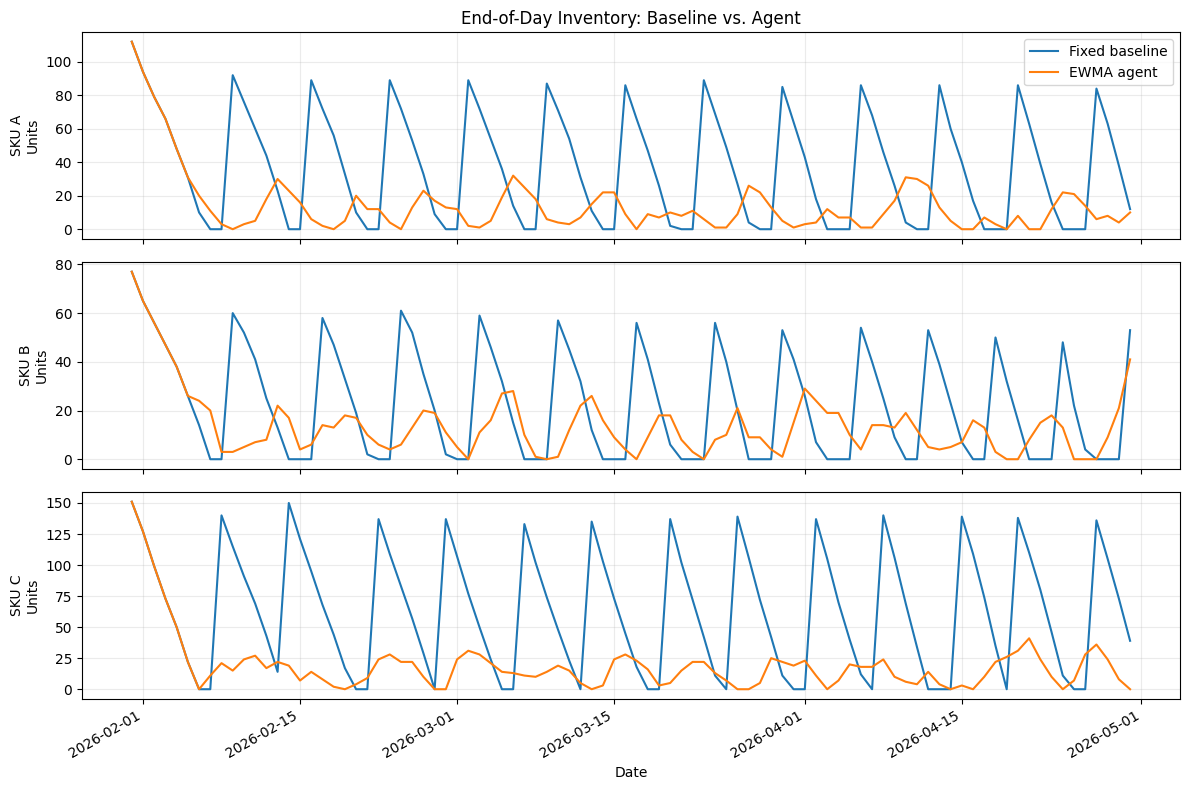


DAILY AGENT LOG
      date sku  forecast  safety_stock  projected_after_lead_time  received  on_hand  order_qty                                      reason
2026-01-31   A     16.63         13.67                      46.85         0      112          0       Wait: position 130 covers target 114.
2026-01-31   B     11.76         11.87                      42.96         0       77          0         Wait: position 90 covers target 71.
2026-01-31   C     25.18         12.83                       3.76         0      151         35 Order 35: position 180 is below target 215.
2026-02-01   A     17.04         13.62                      26.79         0       94         10 Order 10: position 112 is below target 116.
2026-02-01   B     12.13         11.75                      28.47         0       65          0         Wait: position 77 covers target 73.
2026-02-01   C     26.32         13.08                       1.74         0      127         38 Order 38: position 186 is below target 224.
202

In [1]:
# Inventory Replenishment Agent

from pathlib import Path
from statistics import NormalDist
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()

# Adjustable settings
ALPHA = 0.30
WARMUP_DAYS = 30


# ------------------------------------------------------------
# 1. Create reproducible sample data
# ------------------------------------------------------------

def generate_data():
    """Create 120 days of synthetic demand for three products."""
    rng = np.random.default_rng(7)
    rows = []

    for sku, mean in [("A", 15), ("B", 9), ("C", 23)]:
        dates = pd.date_range("2026-01-01", periods=120)

        for day, date in enumerate(dates):
            weekly_pattern = 3 * math.sin(2 * math.pi * day / 7)
            trend = 0.09 * day
            noise = rng.normal(0, 2)

            demand = max(
                0,
                round(mean + weekly_pattern + trend + noise)
            )

            rows.append([date.date(), sku, demand])

    sales = pd.DataFrame(
        rows,
        columns=["date", "sku", "qty_sold"]
    )

    inventory = pd.DataFrame(
        [["A", 130], ["B", 90], ["C", 180]],
        columns=["sku", "opening_stock"]
    )

    params = pd.DataFrame(
        [
            ["A", 5, 0.12, 8, 5, 10, 0.95, 1, 400, 0],
            ["B", 4, 0.12, 8, 4, 10, 0.95, 1, 400, 0],
            ["C", 7, 0.12, 8, 7, 10, 0.95, 1, 400, 0],
        ],
        columns=[
            "sku",
            "unit_cost",
            "holding_cost_per_day",
            "stockout_cost",
            "lead_time_days",
            "min_order_qty",
            "service_level",
            "review_period_days",
            "max_inventory",
            "fixed_order_cost",
        ]
    )

    sales.to_csv(ROOT / "sales.csv", index=False)
    inventory.to_csv(ROOT / "inventory.csv", index=False)
    params.to_csv(ROOT / "params.csv", index=False)


# ------------------------------------------------------------
# 2. Load and validate the CSV files
# ------------------------------------------------------------

def load_data():
    sales = pd.read_csv(
        ROOT / "sales.csv",
        parse_dates=["date"]
    )

    inventory = pd.read_csv(
        ROOT / "inventory.csv"
    ).set_index("sku")

    params = pd.read_csv(
        ROOT / "params.csv"
    ).set_index("sku")

    assert set(sales.sku) == set(inventory.index) == set(params.index), (
        "The SKU lists must match."
    )

    assert not inventory.index.has_duplicates
    assert not params.index.has_duplicates

    assert not sales[["date", "sku", "qty_sold"]].isna().any().any()
    assert (sales.qty_sold >= 0).all()
    assert (sales.qty_sold % 1 == 0).all()

    assert not inventory.isna().any().any()
    assert (inventory.opening_stock >= 0).all()
    assert (inventory.opening_stock % 1 == 0).all()
    assert not params.isna().any().any()

    integer_columns = [
        "lead_time_days",
        "min_order_qty",
        "review_period_days",
        "max_inventory",
    ]

    for column in integer_columns:
        assert (params[column] >= 1).all()
        assert (params[column] % 1 == 0).all()

    assert (
        (params.service_level > 0.5)
        & (params.service_level < 1)
    ).all()

    assert (
        params.max_inventory >= params.min_order_qty
    ).all()

    assert (
        inventory.opening_stock <= params.max_inventory
    ).all()

    cost_columns = [
        "unit_cost",
        "holding_cost_per_day",
        "stockout_cost",
        "fixed_order_cost",
    ]

    assert (params[cost_columns] >= 0).all().all()

    # Combine multiple records for the same product and day.
    daily = (
        sales.groupby(["date", "sku"])["qty_sold"]
        .sum()
        .unstack("sku")
    )

    all_dates = pd.date_range(
        sales.date.min(),
        sales.date.max()
    )

    daily = daily.reindex(all_dates)
    daily.index.name = "date"

    # Missing records are not automatically treated as zero demand.
    assert not daily.isna().any().any(), (
        "Missing daily records. Check the data before running."
    )

    return daily, inventory, params


# ------------------------------------------------------------
# 3. Simulate the baseline or the replenishment agent
# ------------------------------------------------------------

def simulate(
    daily,
    inventory,
    params,
    policy="ewma",
    alpha=ALPHA,
    warmup=WARMUP_DAYS
):
    """
    Daily sequence:
    1. Receive orders.
    2. Decide using previously observed demand.
    3. Serve today's demand.
    4. Update the forecast.

    An order placed on day t arrives at the start of day t + lead time.
    Unmet demand is treated as lost sales, not backlog.
    """

    assert policy in ["fixed", "ewma"]
    assert 0 < alpha <= 1
    assert 2 <= warmup < len(daily)

    records = []
    orders = []

    for sku in daily.columns:
        p = params.loc[sku]

        lead_time = int(p.lead_time_days)
        review_period = int(p.review_period_days)
        minimum_order = int(p.min_order_qty)
        inventory_cap = int(p.max_inventory)

        # Use only the initialization period to start the model.
        training = daily[sku].iloc[:warmup].to_numpy()

        forecast = float(training[0])
        forecast_errors = []

        for actual in training[1:]:
            forecast_errors.append(float(actual - forecast))
            forecast = alpha * actual + (1 - alpha) * forecast

        # Simple fixed baseline: no demand updates or safety stock.
        fixed_mean = float(training.mean())
        fixed_reorder_point = math.ceil(fixed_mean * lead_time)
        fixed_order_quantity = max(
            minimum_order,
            math.ceil(fixed_mean * 7)
        )

        # Opening stock applies at the start of evaluation.
        stock = int(inventory.loc[sku, "opening_stock"])
        pipeline = []

        for day in range(warmup, len(daily)):
            date = daily.index[day]

            # Receive purchase orders due today.
            received = sum(
                quantity
                for due_day, quantity in pipeline
                if due_day == day
            )

            pipeline = [
                (due_day, quantity)
                for due_day, quantity in pipeline
                if due_day > day
            ]

            stock += received

            on_order_before = sum(
                quantity for _, quantity in pipeline
            )

            inventory_position = stock + on_order_before

            # Use the most recent 28 historical forecast errors.
            recent_errors = forecast_errors[-28:]

            error_rmse = float(
                np.sqrt(np.mean(np.square(recent_errors)))
            )

            z_score = NormalDist().inv_cdf(
                float(p.service_level)
            )

            protection_period = lead_time + review_period

            safety_stock = (
                z_score
                * error_rmse
                * math.sqrt(protection_period)
            )

            target = min(
                inventory_cap,
                math.ceil(
                    forecast * protection_period + safety_stock
                )
            )

            projected_inventory = (
                inventory_position - forecast * lead_time
            )

            order_quantity = 0

            if (day - warmup) % review_period != 0:
                reason = "Wait: next review date."

            elif policy == "ewma":
                if inventory_position < target:
                    desired_quantity = max(
                        minimum_order,
                        target - inventory_position
                    )

                    available_capacity = (
                        inventory_cap - inventory_position
                    )

                    order_quantity = min(
                        desired_quantity,
                        available_capacity
                    )

                    if order_quantity < minimum_order:
                        order_quantity = 0
                        reason = (
                            "Wait: inventory cap leaves less "
                            "room than the minimum order."
                        )
                    else:
                        reason = (
                            f"Order {order_quantity}: position "
                            f"{inventory_position} is below "
                            f"target {target}."
                        )

                else:
                    reason = (
                        f"Wait: position {inventory_position} "
                        f"covers target {target}."
                    )

            else:
                if inventory_position <= fixed_reorder_point:
                    order_quantity = min(
                        fixed_order_quantity,
                        inventory_cap - inventory_position
                    )

                    if order_quantity < minimum_order:
                        order_quantity = 0
                        reason = (
                            "Wait: inventory cap prevents "
                            "the minimum order."
                        )
                    else:
                        reason = (
                            f"Fixed rule: position "
                            f"{inventory_position} is at or below "
                            f"reorder point {fixed_reorder_point}."
                        )
                else:
                    reason = (
                        f"Wait: position {inventory_position} "
                        f"exceeds fixed reorder point "
                        f"{fixed_reorder_point}."
                    )

            if order_quantity > 0:
                pipeline.append(
                    (day + lead_time, order_quantity)
                )

                orders.append({
                    "policy": policy,
                    "sku": sku,
                    "date": date,
                    "arrival_date": (
                        date + pd.Timedelta(days=lead_time)
                    ),
                    "qty": order_quantity,
                })

            # Demand becomes known after today's decision.
            actual_demand = int(daily[sku].iloc[day])
            served = min(stock, actual_demand)
            lost_units = actual_demand - served
            stock -= served

            holding_cost = stock * p.holding_cost_per_day
            stockout_cost = lost_units * p.stockout_cost

            order_cost = (
                float(p.fixed_order_cost)
                if order_quantity > 0
                else 0.0
            )

            records.append({
                "policy": policy,
                "date": date,
                "sku": sku,
                "demand": actual_demand,
                "served": served,
                "lost_units": lost_units,
                "stockout_day": int(lost_units > 0),
                "received": received,
                "on_hand": stock,
                "on_order": sum(q for _, q in pipeline),
                "inventory_position": inventory_position,
                "forecast": forecast,
                "forecast_error": actual_demand - forecast,
                "safety_stock": safety_stock,
                "projected_after_lead_time": projected_inventory,
                "target": target,
                "order_qty": order_quantity,
                "holding_cost": holding_cost,
                "stockout_cost": stockout_cost,
                "order_cost": order_cost,
                "purchase_spend": order_quantity * p.unit_cost,
                "reason": reason,
            })

            # Update only after observing today's demand.
            forecast_errors.append(actual_demand - forecast)

            forecast = (
                alpha * actual_demand
                + (1 - alpha) * forecast
            )

    log = pd.DataFrame(records)

    orders = pd.DataFrame(
        orders,
        columns=[
            "policy", "sku", "date", "arrival_date", "qty"
        ]
    )

    total_demand = int(log.demand.sum())
    total_served = int(log.served.sum())

    metrics = {
        "policy": policy,
        "demand": total_demand,
        "served": total_served,
        "lost_units": int(log.lost_units.sum()),
        "stockout_sku_days": int(log.stockout_day.sum()),
        "fill_rate": (
            total_served / total_demand
            if total_demand > 0
            else 1.0
        ),
        "holding_cost": float(log.holding_cost.sum()),
        "stockout_cost": float(log.stockout_cost.sum()),
        "order_cost": float(log.order_cost.sum()),
        "purchase_spend": float(log.purchase_spend.sum()),
        "average_on_hand": float(log.on_hand.mean()),
        "forecast_mae": float(log.forecast_error.abs().mean()),
    }

    # Purchase spending is reported separately from operating cost.
    metrics["total_cost"] = (
        metrics["holding_cost"]
        + metrics["stockout_cost"]
        + metrics["order_cost"]
    )

    return log, orders, metrics


# ------------------------------------------------------------
# 4. Check inventory accounting and business rules
# ------------------------------------------------------------

def verify_results(log, orders, metrics, inventory, params):
    assert (log.served + log.lost_units == log.demand).all()
    assert (log.on_hand >= 0).all()

    for sku, group in log.groupby("sku"):
        p = params.loc[sku]

        assert (
            (group.order_qty == 0)
            | (group.order_qty >= p.min_order_qty)
        ).all()

        assert (
            group.on_hand + group.on_order <= p.max_inventory
        ).all()

        opening_stock = inventory.loc[sku, "opening_stock"]

        expected_stock = (
            opening_stock
            + group.received.cumsum()
            - group.served.cumsum()
        )

        assert (expected_stock == group.on_hand).all()

        expected_arrivals = {}

        for _, order in orders[orders.sku == sku].iterrows():
            assert (
                order.arrival_date - order.date
            ).days == p.lead_time_days

            expected_arrivals[order.arrival_date] = (
                expected_arrivals.get(order.arrival_date, 0)
                + order.qty
            )

        for _, row in group.iterrows():
            assert row.received == expected_arrivals.get(
                row.date, 0
            )

    expected_cost = (
        log.holding_cost
        + log.stockout_cost
        + log.order_cost
    ).sum()

    assert math.isclose(
        metrics["total_cost"],
        expected_cost,
        abs_tol=1e-8
    )


# ------------------------------------------------------------
# 5. Run both strategies
# ------------------------------------------------------------

input_files = [
    ROOT / "sales.csv",
    ROOT / "inventory.csv",
    ROOT / "params.csv",
]

if not any(path.exists() for path in input_files):
    generate_data()
elif not all(path.exists() for path in input_files):
    raise ValueError(
        "Upload all three input CSVs, or remove partial inputs "
        "to generate the sample dataset."
    )

daily, inventory, params = load_data()

print("DATA")
print("Synthetic sample data: 120 days and 3 SKUs.")
print("First 30 days: forecast initialization.")
print("Remaining 90 days: evaluation.")
display(daily.head())
display(params.reset_index())

logs = {}
purchase_orders = {}
results = []

for policy in ["fixed", "ewma"]:
    log, orders, metrics = simulate(
        daily,
        inventory,
        params,
        policy=policy
    )

    verify_results(
        log,
        orders,
        metrics,
        inventory,
        params
    )

    logs[policy] = log
    purchase_orders[policy] = orders
    results.append(metrics)

    log.to_csv(
        ROOT / f"{policy}_daily_log.csv",
        index=False
    )

    orders.to_csv(
        ROOT / f"{policy}_purchase_orders.csv",
        index=False
    )

metrics_table = pd.DataFrame(results)
metrics_table.to_csv(ROOT / "metrics.csv", index=False)

print("\nRESULTS")
display(
    metrics_table.style.format({
        "fill_rate": "{:.2%}",
        "holding_cost": "${:,.2f}",
        "stockout_cost": "${:,.2f}",
        "order_cost": "${:,.2f}",
        "total_cost": "${:,.2f}",
        "purchase_spend": "${:,.2f}",
        "average_on_hand": "{:.2f}",
        "forecast_mae": "{:.2f}",
    })
)

print(
    "\nChecks passed: inventory accounting, nonnegative stock, "
    "minimum orders, inventory caps, arrival timing, and costs."
)


# ------------------------------------------------------------
# 6. Compare the outcomes
# ------------------------------------------------------------

baseline = metrics_table.set_index("policy").loc["fixed"]
agent = metrics_table.set_index("policy").loc["ewma"]

fill_improvement = (
    agent.fill_rate - baseline.fill_rate
) * 100

print("\nBASELINE COMPARISON")
print(f"Baseline fill rate: {baseline.fill_rate:.2%}")
print(f"Agent fill rate: {agent.fill_rate:.2%}")
print(
    f"Fill-rate improvement: "
    f"{fill_improvement:.2f} percentage points"
)

if baseline.total_cost > 0:
    cost_reduction = (
        (baseline.total_cost - agent.total_cost)
        / baseline.total_cost
        * 100
    )
    print(f"Operating-cost reduction: {cost_reduction:.2f}%")

print(
    "\nTotal operating cost = holding cost + stockout cost "
    "+ fixed order cost."
)

print(
    "Purchase spending is reported separately and includes "
    "orders still in transit at the end."
)


# ------------------------------------------------------------
# 7. Plot inventory levels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    sharex=True
)

for ax, sku in zip(axes, daily.columns):
    for policy, label in [
        ("fixed", "Fixed baseline"),
        ("ewma", "EWMA agent")
    ]:
        product_log = logs[policy][logs[policy].sku == sku]

        ax.plot(
            product_log.date,
            product_log.on_hand,
            label=label
        )

    ax.set_ylabel(f"SKU {sku}\nUnits")
    ax.grid(alpha=0.25)

axes[0].set_title("End-of-Day Inventory: Baseline vs. Agent")
axes[0].legend()
axes[-1].set_xlabel("Date")

fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(
    ROOT / "inventory_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 8. Print and save the daily agent log
# ------------------------------------------------------------

log_columns = [
    "date",
    "sku",
    "forecast",
    "safety_stock",
    "projected_after_lead_time",
    "received",
    "on_hand",
    "order_qty",
    "reason",
]

daily_agent_log = (
    logs["ewma"][log_columns]
    .sort_values(["date", "sku"])
)

log_text = daily_agent_log.to_string(
    index=False,
    float_format=lambda value: f"{value:.2f}"
)

print("\nDAILY AGENT LOG")
print(log_text)

(ROOT / "successful_output.txt").write_text(
    "Inventory Replenishment Agent\n\n"
    + metrics_table.to_string(index=False)
    + "\n\nDaily Agent Log\n"
    + log_text,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 9. Design, reflection, and scaling explanation
# ------------------------------------------------------------

print("""
AGENT DESIGN

Goal:
The agent helps a business decide when to order more products
and how much to order. The goal is to avoid running out while
keeping inventory costs under control.

Inputs:
It uses past demand, available stock, incoming orders, delivery
times, costs, and the minimum amount allowed per order.

Outputs:
Each day, the agent either recommends an order or decides to
wait. It also explains why it made that decision.

Forecast:
The agent estimates future demand using EWMA. This method gives
more weight to recent demand and updates after each day.

Safety stock:
The agent keeps extra stock as a backup when demand is higher
than expected. This amount depends on past forecasting mistakes,
delivery time, and the chosen service level.

Ordering:
The agent checks whether available stock and incoming orders
will cover expected demand during the delivery and review period.
If there is not enough, it recommends ordering more.

Rules:
Orders must meet the minimum quantity and stay within the
inventory limit. The agent includes incoming orders so it does
not order too much. If daily records are missing, it stops
instead of making decisions with incomplete information.

Measuring success:
We track how many units customers receive, how many units cannot
be supplied, and how many product-days have a shortage.
Fill rate is the percentage of demand served right away.
Total operating cost includes holding costs, shortage penalties,
and fixed ordering fees. Product purchase spending is shown
separately.

Trust:
Keeping products available helps customers trust the business.
Avoiding excess stock also protects the business's money.
The daily log makes each decision easy to review. A buyer should
check the recommendations before using them for real orders.


REFLECTION

The baseline uses the same demand estimate throughout the test.
The agent updates its estimate every day, which helps it respond
when demand changes.

In this test, the agent filled more demand and had lower holding
and shortage costs than the baseline. Ordering smaller amounts
more often helped it keep less stock while avoiding shortages.

There is still a balance to consider. More backup stock can
prevent shortages, but it also costs money to store. Frequent
orders could become expensive if suppliers charge a fee for
each order. This test assumes that fixed ordering fee is zero.

The 95% service setting helps determine backup stock. It does
not guarantee that exactly 95% of demand will be filled.

These results use made-up sample data and one simple baseline.
They show how the agent works, but they do not prove the same
savings would happen in a real business. More testing should
include different demand patterns, delivery delays, and other
ordering strategies. Unfilled demand is counted as lost sales
rather than being carried over to the next day.


SCALING NOTE

To use this for more products, the business could run the agent
automatically in the cloud each day. It would collect updated
sales, stock levels, and incoming orders, then prepare
recommendations for a buyer to review.

The business should monitor shortages, fill rate, forecast
mistakes, and late deliveries. If results get worse or data is
missing, the system should alert someone.

If a connection fails, the system should try again a limited
number of times. It should also check whether an order was
already created so that retrying does not cause duplicate orders.

Inventory limits and purchasing budgets would help control
spending. The business should start with a small group of
products and expand after checking that the agent works well.
""")

print("\nFinished. Output files are available in Colab's Files panel.")